# Milestone 2 — analyze the randomized retention experiment

**After the World Cup brings in free-trial customers, which action improves paid retention enough to be worth its cost?**

This walkthrough analyzes the experiment defined in Milestone 1. We compare each action with no special offer, keeping **all randomized customers** in the analysis. We estimate average effects and their uncertainty; a higher sample average is not enough to name a winner.

You will inspect randomization, estimate primary paid-retention differences, examine secondary conversion and revenue differences, and finally compare retention estimates with a separate simulation answer key. No ML targeting, uplift model, or dbt is built here.

These customers and response patterns are synthetic. Inference describes repeated experiments under the simulated scenario; it does not establish real-world customer behavior. See [`docs/assumptions.md`](../docs/assumptions.md) for the data-generating assumptions and [`docs/experiment_analysis.md`](../docs/experiment_analysis.md) for the analysis plan.


## 1. Set up and specify the comparison plan

Install `requirements.txt` from the repository root, start Jupyter Lab, and run this notebook from top to bottom. You do not need to execute Milestone 1 first: this notebook regenerates data with the **unchanged simulator**, using the same default sample size and seed. It saves its own files under ignored `data/milestone2/`, preserving Milestone 1's exports.

For Colab, clone `https://github.com/KDHAN123/Customer-decisioning-platform.git` with branch `milestone-1-synthetic-experiment`, `%cd /content/Customer-decisioning-platform`, and `%pip install -r requirements.txt` before running these cells. Uploading only a notebook does not include its imported modules.

We set the analysis plan **before inspecting outcomes**:

* Primary family: two offer-versus-control comparisons of `retained_day90`, two-sided, family error level 5%.
* Separate exploratory family: six comparisons (two offers × conversion and two revenue measures), also two-sided with family error level 5%.
* Bonferroni adjusts p-values and confidence intervals within each family. There is no joint 5% guarantee across both families; secondary results support exploration and do not substitute for the primary outcome.
* No subgroup search, offer-versus-offer test, repeated peeking, outcome-dependent exclusions, or feature-adjusted model is planned.

Reusable statistical helpers live in `retention/analysis.py` so their calculations can be tested. The interpretation stays in this notebook.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'retention' / 'simulation.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Clone the repository and change to its directory before running.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from retention.simulation import ARMS, PRE_OFFER_FEATURES, simulate_experiment
from retention.analysis import compare_binary, compare_revenue

N_CUSTOMERS = 12_000
SEED = 2026
ALPHA = .05
PRIMARY_FAMILY_SIZE = 2
SECONDARY_FAMILY_SIZE = 6
RUN_DIR = ROOT / 'data' / 'milestone2'
print(f'{N_CUSTOMERS:,} customers; seed={SEED}; primary alpha={ALPHA}')
print(f'NumPy {np.__version__}; pandas {pd.__version__}; SciPy {scipy.__version__}')


12,000 customers; seed=2026; primary alpha=0.05
NumPy 2.3.5; pandas 2.2.3; SciPy 1.17.0


## 2. Generate the existing three-group experiment

Customers enter the experiment on trial day 13 if they are still active (viewing on at least one of the preceding three completed days) and have not canceled. The simulator generates this eligible cohort directly; it does not represent every signup.

| Group | Assigned action |
|---|---|
| `control` | No special offer; standard $15/month plan |
| `content_recommendation` | Recommend relevant non-World-Cup content at the same subscription price; $0.10 delivery cost per assignment |
| `discount_20pct` | 20% off the first paid month, then standard subscription price |

Each customer has an independent **1/3** chance of each action. All behavioral features describe the 13 completed days **before** the offer. The scheduled trial end remains day 14 in every arm.

**Primary outcome:** converted and still paying 90 days after scheduled trial end. **Secondary conversion:** converted by scheduled trial end. Nonconverters have zero subscription revenue and count as not retained. We never restrict the main analysis to converters or retained customers: those outcomes can be affected by the action, so conditioning on them breaks the randomized comparison.

The simulator also produces an oracle key. The next cell writes it to a separate evaluation folder without inspecting or using its values, then removes it from memory. It will be opened **only in the final diagnostic**, after observed-data inference and interpretation are complete.


In [2]:
customers, generated_key = simulate_experiment(N_CUSTOMERS, SEED)
observed_dir = RUN_DIR / 'generated'
evaluation_dir = RUN_DIR / 'evaluation_only'
observed_dir.mkdir(parents=True, exist_ok=True)
evaluation_dir.mkdir(parents=True, exist_ok=True)
customers.to_csv(observed_dir / 'customers.csv', index=False)
ORACLE_PATH = evaluation_dir / 'oracle_probabilities.csv'
generated_key.to_csv(ORACLE_PATH, index=False)
del generated_key
metadata = {'n_customers': N_CUSTOMERS, 'seed': SEED,
            'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'primary_alpha': ALPHA, 'primary_family_size': PRIMARY_FAMILY_SIZE,
            'secondary_family_size': SECONDARY_FAMILY_SIZE,
            'followup_anchor': 'scheduled_trial_end_date', 'followup_days': 90}
(observed_dir / 'analysis_run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')

# Observed-data checks only: no answer key needed for analysis.
assert len(customers) == N_CUSTOMERS and customers.customer_id.is_unique
assert customers.eligible_at_offer.all() and customers.active_at_offer.all()
assert not customers.canceled_before_offer.any()
assert customers.active_days_last3_pre.ge(1).all()
assert customers.feature_window_end_date.eq(customers.assignment_date).all()
assert (customers.scheduled_trial_end_date - customers.assignment_date).dt.days.eq(1).all()
assert (customers.followup_end_date - customers.scheduled_trial_end_date).dt.days.eq(90).all()
assert customers.assignment_probability.eq(1 / 3).all()
assert not any(c.startswith(('p_', 'effect_')) for c in customers.columns)
assert (~customers.retained_day90 | customers.converted).all()
assert customers[['retained_day90', 'converted', 'subscription_revenue_90',
                  'revenue_less_delivery_cost_90']].notna().all().all()
print('Generated complete observed data; oracle saved separately, not used for inference.')
display(customers[['customer_id', 'assignment_date', 'scheduled_trial_end_date',
                   'followup_end_date', 'assigned_offer']].head())


Generated complete observed data; oracle saved separately, not used for inference.


,customer_id,assignment_date,scheduled_trial_end_date,followup_end_date,assigned_offer
0,customer_0000001,2026-07-06,2026-07-07,2026-10-05,discount_20pct
1,customer_0000002,2026-06-23,2026-06-24,2026-09-22,discount_20pct
2,customer_0000003,2026-07-14,2026-07-15,2026-10-13,content_recommendation
3,customer_0000004,2026-07-17,2026-07-18,2026-10-16,control
4,customer_0000005,2026-07-10,2026-07-11,2026-10-09,control


## 3. Inspect assignment and pre-offer balance

Random assignment should give roughly one third of customers to each action. Unequal counts are expected: the simulator does not force equal-sized groups.

We show means and standard deviations of pre-offer behavior, plus each offer's standardized mean difference from control: `(offer mean − control mean) / pooled within-group standard deviation`. Values near zero suggest similar starting behavior; 0.1 is a common descriptive reference, not a pass/fail criterion. Balance does not prove randomization, and a chance difference is not a reason to drop customers or redraw assignment until it looks favorable. No balance hypothesis tests are used.


,assigned_customers,share
assigned_offer,,
control,3999,0.333
content_recommendation,3970,0.331
discount_20pct,4031,0.336


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
Pre-offer means by group,,,,,,,,
control,7.06,2.01,9.26,0.59,3.77,2.62,1.54,2.88
content_recommendation,7.00,2.01,8.96,0.60,3.59,2.62,1.57,2.82
discount_20pct,6.99,2.02,9.08,0.60,3.66,2.63,1.56,2.83


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
Pre-offer standard deviations by group,,,,,,,,
control,2.46,0.75,7.52,0.2,3.94,1.21,1.34,2.14
content_recommendation,2.48,0.74,7.35,0.2,3.69,1.20,1.34,2.09
discount_20pct,2.48,0.74,7.57,0.2,3.90,1.20,1.38,2.16


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
Standardized offer − control differences,,,,,,,,
content_recommendation,-0.022,-0.001,-0.040,0.020,-0.049,0.00,0.021,-0.027
discount_20pct,-0.026,0.009,-0.024,0.015,-0.030,0.01,0.010,-0.023


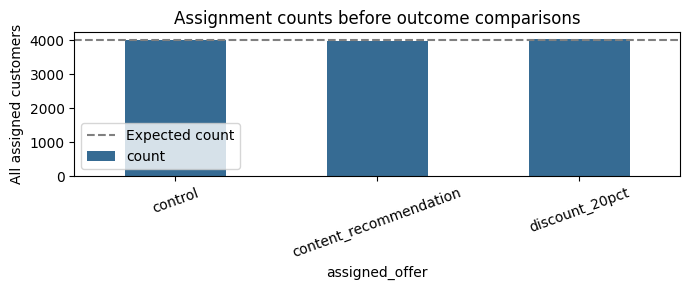

In [3]:
counts = customers.assigned_offer.value_counts().reindex(ARMS)
assert counts.sum() == len(customers) and counts.gt(0).all()
display(pd.DataFrame({'assigned_customers': counts, 'share': counts / len(customers)}).round(3))
features = customers.loc[:, ['assigned_offer', *PRE_OFFER_FEATURES]]
feature_means = features.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].mean().reindex(ARMS)
feature_sds = features.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].std().reindex(ARMS)
display(feature_means.round(2).rename_axis('Pre-offer means by group'))
display(feature_sds.round(2).rename_axis('Pre-offer standard deviations by group'))
standardized_differences = pd.DataFrame(index=ARMS[1:], columns=PRE_OFFER_FEATURES, dtype=float)
for offer in ARMS[1:]:
    pooled_sd = np.sqrt(((counts[offer] - 1) * feature_sds.loc[offer] ** 2
                       + (counts['control'] - 1) * feature_sds.loc['control'] ** 2)
                       / (counts[offer] + counts['control'] - 2))
    standardized_differences.loc[offer] = (feature_means.loc[offer] - feature_means.loc['control']) / pooled_sd.replace(0, np.nan)
display(standardized_differences.round(3).rename_axis('Standardized offer − control differences'))
counts.plot.bar(figsize=(7, 3), rot=20, color='#366b93')
plt.axhline(len(customers) / 3, color='gray', linestyle='--', label='Expected count')
plt.ylabel('All assigned customers')
plt.title('Assignment counts before outcome comparisons')
plt.legend()
plt.tight_layout()
plt.show()


## 4. Define outcome denominators and the economic ledger

Our estimand is the **average effect of assigning each action rather than control** in the eligible trial population. With independent randomization, complete follow-up, and no cross-customer interference, the difference in arm averages estimates this effect. No compliance correction is needed in this simulator. Every assigned customer contributes one outcome to the arm they were assigned, including nonconverters.

`subscription_revenue_90` is subscription revenue accrued during the 90-day trial-end window, **after the first-month discount**. Nonconverters contribute $0. The simulator uses $0.50/day and prorates cancellations.

`revenue_less_delivery_cost_90` subtracts recommendation delivery costs from that subscription revenue ($0.10 for every recommendation assignment). Recommendation nonconverters contribute −$0.10. Discounts are already subtracted in subscription revenue; subtracting total offer cost again would count discounts twice.

Neither measure includes acquisition, baseline hosting, licensing, taxes, fixed costs, or other operating expenses. Neither is profit; a positive revenue difference does not establish profitability.

The descriptive table is a starting point. We need confidence intervals and tests to distinguish plausible effects from random variation.


In [4]:
summary = customers.groupby('assigned_offer').agg(
    assigned_customers=('customer_id', 'size'),
    retained_customers=('retained_day90', 'sum'),
    retention_rate=('retained_day90', 'mean'),
    converted_customers=('converted', 'sum'),
    conversion_rate=('converted', 'mean'),
    subscription_revenue_per_assigned=('subscription_revenue_90', 'mean'),
    revenue_less_delivery_per_assigned=('revenue_less_delivery_cost_90', 'mean'),
    offer_cost_per_assigned=('offer_cost_90', 'mean'),
).reindex(ARMS)
assert summary.assigned_customers.equals(counts.rename('assigned_customers'))
assert summary.assigned_customers.sum() == len(customers)
display(summary.round(3))


,assigned_customers,retained_customers,retention_rate,converted_customers,conversion_rate,subscription_revenue_per_assigned,revenue_less_delivery_per_assigned,offer_cost_per_assigned
assigned_offer,,,,,,,,
control,3999,706,0.177,1435,0.359,11.581,11.581,0.000
content_recommendation,3970,714,0.180,1418,0.357,11.788,11.688,0.100
discount_20pct,4031,619,0.154,1253,0.311,9.230,9.230,0.835


## 5. Primary analysis: paid retention at scheduled trial end + 90

For each offer, subtract the control retention rate from the offer retention rate. We report **percentage points (pp)**: a change from 17% to 19% is +2 pp, not a 2% relative increase.

We test a two-sided null of equal retention probabilities with a pooled **two-proportion z test**. The effect's uncertainty uses an unpooled standard error `sqrt(p_offer(1−p_offer)/n_offer + p_control(1−p_control)/n_control)` and a normal (Wald) interval. The observed groups have thousands of customers and ample successes and failures; the helper refuses sparse samples where these approximations are unsuitable.

For the two planned primary comparisons, Bonferroni multiplies each raw p-value by 2 (capped at 1). Each adjusted interval has **97.5% marginal confidence**, providing approximately at least **95% simultaneous coverage** for the two effects under the normal approximation. This works despite the shared control, though it is conservative. The table also shows ordinary pointwise 95% intervals for context; decisions use adjusted p-values and adjusted intervals. The pooled test and unpooled interval use different variance estimates, so borderline conclusions can differ slightly.

A p-value is not the probability the null is true. A frequentist confidence interval describes a method's long-run coverage, not a probability distribution on this particular effect. An interval crossing zero leaves both signs plausible and does not prove no effect. Statistical significance also does not say the effect is economically large enough.


Retention effects and intervals in percentage points; adjusted intervals protect the two-comparison family.


,outcome,offer,n_control,n_offer,estimate,ci_low,ci_high,ci_adjusted_low,ci_adjusted_high,p_value,p_adjusted
0,retained_day90,content_recommendation,3999,3970,0.3305,-1.3499,2.0109,-1.5912,2.2522,0.6999,1
1,retained_day90,discount_20pct,3999,4031,-2.2984,-3.9217,-0.6751,-4.1548,-0.4420,0.005531,0.01106


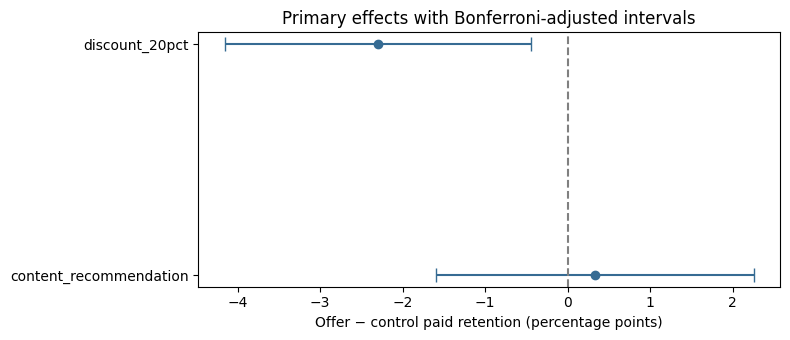

In [5]:
primary = compare_binary(customers, 'retained_day90', alpha=ALPHA, family_size=PRIMARY_FAMILY_SIZE)
assert primary.n_control.eq(counts['control']).all()
for row in primary.itertuples():
    assert row.n_offer == counts[row.offer]

# Helpers return fractions; convert only binary effects and intervals to pp.
def display_effects(results, binary=False):
    shown = results[['outcome', 'offer', 'n_control', 'n_offer', 'estimate',
                     'ci_low', 'ci_high', 'ci_adjusted_low', 'ci_adjusted_high',
                     'p_value', 'p_adjusted']].copy()
    if binary:
        for col in ['estimate', 'ci_low', 'ci_high', 'ci_adjusted_low', 'ci_adjusted_high']:
            shown[col] *= 100
    shown = shown.round({col: 4 for col in shown.columns if col not in ['p_value', 'p_adjusted']})
    for col in ['p_value', 'p_adjusted']:
        shown[col] = shown[col].map(lambda value: f'{value:.4g}')
    return shown

print('Retention effects and intervals in percentage points; adjusted intervals protect the two-comparison family.')
display(display_effects(primary, binary=True))
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(primary))
ax.errorbar(primary.estimate * 100, y,
            xerr=np.vstack([(primary.estimate - primary.ci_adjusted_low) * 100,
                            (primary.ci_adjusted_high - primary.estimate) * 100]),
            fmt='o', capsize=5, color='#366b93')
ax.axvline(0, color='gray', linestyle='--')
ax.set_yticks(y, primary.offer)
ax.set_xlabel('Offer − control paid retention (percentage points)')
ax.set_title('Primary effects with Bonferroni-adjusted intervals')
plt.tight_layout()
plt.show()


### Read the primary results without picking a winner

The following text reports this run's effect size, adjusted interval, and test evidence. It does not rank actions by their point estimates. Offer-versus-control tests also do not establish that one offer outperforms the other.


In [6]:
for row in primary.itertuples():
    if row.p_adjusted < ALPHA:
        evidence = 'evidence of a positive average retention effect' if row.estimate > 0 else 'evidence of a negative average retention effect'
    else:
        evidence = 'insufficient evidence to distinguish the average retention effect from zero'
    print(f'{row.offer}: {100 * row.estimate:+.2f} pp; adjusted interval '
          f'[{100 * row.ci_adjusted_low:+.2f}, {100 * row.ci_adjusted_high:+.2f}] pp; '
          f'adjusted p={row.p_adjusted:.4f}. This run provides {evidence}.')
print('No deployment winner is established by these comparisons alone.')


content_recommendation: +0.33 pp; adjusted interval [-1.59, +2.25] pp; adjusted p=1.0000. This run provides insufficient evidence to distinguish the average retention effect from zero.
discount_20pct: -2.30 pp; adjusted interval [-4.15, -0.44] pp; adjusted p=0.0111. This run provides evidence of a negative average retention effect.
No deployment winner is established by these comparisons alone.


## 6. Secondary conversion and revenue comparisons

Conversion is secondary, not a replacement for primary paid retention. Revenue can fall despite conversion gains if discounts cost more than they bring in; recommendation delivery costs also apply to nonconverters.

We compare conversion with the same proportion method. For each revenue measure, we estimate an **arithmetic mean difference in USD per assigned customer** with a two-sided **Welch t test** and Welch confidence interval. Welch allows different arm variances. Revenue is skewed and has many zeroes, but thousands of independent customers per group make normal approximation of the sample means reasonable here. These methods would need reconsideration for small groups, extreme heavy tails, dependent households, or missing follow-up. We do not log-transform revenue or omit zeroes/negative values, because that would change the business quantity being estimated.

These six exploratory comparisons form their own family. Bonferroni multiplies raw p-values by 6; adjusted intervals are **99.1667% marginal intervals**, giving approximately at least 95% joint coverage within this secondary family. The two revenue metrics are closely related, not independent replications. This family is separate from primary inference; do not search it for a favorable result and then redefine success.


Secondary conversion effects in percentage points:


,outcome,offer,n_control,n_offer,estimate,ci_low,ci_high,ci_adjusted_low,ci_adjusted_high,p_value,p_adjusted
0,converted,content_recommendation,3999,3970,-0.1661,-2.2713,1.9391,-2.9998,2.6676,0.8771,1
1,converted,discount_20pct,3999,4031,-4.7999,-6.8618,-2.7379,-7.5754,-2.0244,5.183e-06,3.11e-05


Revenue effects in USD per assigned customer; these are not profit:


,outcome,offer,n_control,n_offer,estimate,ci_low,ci_high,ci_adjusted_low,ci_adjusted_high,p_value,p_adjusted
0,subscription_revenue_90,content_recommendation,3999,3970,0.2063,-0.5917,1.0042,-0.8680,1.2805,0.6124,1
1,subscription_revenue_90,discount_20pct,3999,4031,-2.3510,-3.0989,-1.6030,-3.3578,-1.3441,7.545e-10,4.527e-09
2,revenue_less_delivery_cost_90,content_recommendation,3999,3970,0.1063,-0.6917,0.9042,-0.9680,1.1805,0.7941,1
3,revenue_less_delivery_cost_90,discount_20pct,3999,4031,-2.3510,-3.0989,-1.6030,-3.3578,-1.3441,7.545e-10,4.527e-09


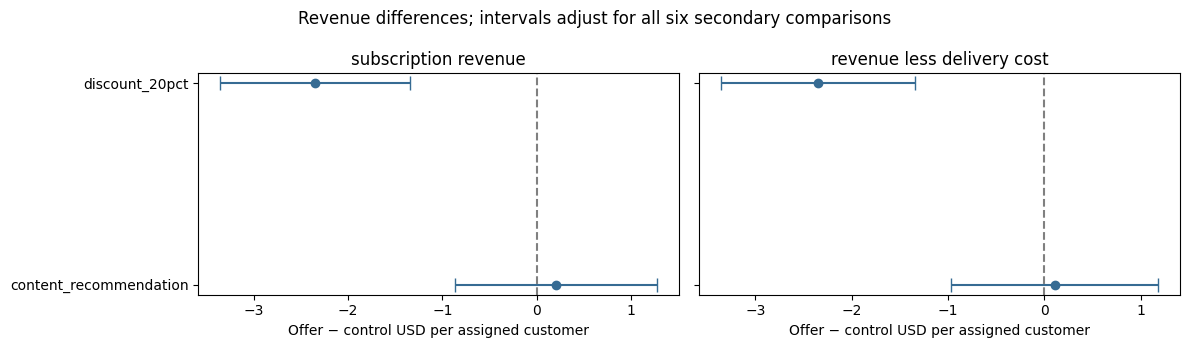

In [7]:
conversion = compare_binary(customers, 'converted', alpha=ALPHA, family_size=SECONDARY_FAMILY_SIZE)
revenue = pd.concat([
    compare_revenue(customers, outcome, alpha=ALPHA, family_size=SECONDARY_FAMILY_SIZE)
    for outcome in ['subscription_revenue_90', 'revenue_less_delivery_cost_90']
], ignore_index=True)
assert len(conversion) + len(revenue) == SECONDARY_FAMILY_SIZE
for table in [conversion, revenue]:
    assert table.n_control.eq(counts['control']).all()
    for row in table.itertuples():
        assert row.n_offer == counts[row.offer]
print('Secondary conversion effects in percentage points:')
display(display_effects(conversion, binary=True))
print('Revenue effects in USD per assigned customer; these are not profit:')
display(display_effects(revenue))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, outcome in zip(axes, ['subscription_revenue_90', 'revenue_less_delivery_cost_90']):
    result = revenue[revenue.outcome.eq(outcome)]
    ax.errorbar(result.estimate, np.arange(len(result)),
                xerr=np.vstack([result.estimate - result.ci_adjusted_low,
                                result.ci_adjusted_high - result.estimate]),
                fmt='o', capsize=5, color='#366b93')
    ax.axvline(0, color='gray', linestyle='--')
    ax.set_yticks(np.arange(len(result)), result.offer)
    ax.set_xlabel('Offer − control USD per assigned customer')
    ax.set_title(outcome.replace('_90', '').replace('_', ' '))
plt.suptitle('Revenue differences; intervals adjust for all six secondary comparisons')
plt.tight_layout()
plt.show()


## 7. Bring the evidence together

Read retention and revenue uncertainty together. A positive point estimate alone is not a sufficient reason to deploy. We have not supplied an economic decision threshold (for example, a minimum acceptable retention gain), complete operating costs, or a real-world replication. Do not invent one after seeing the results.

The next table places the adjusted retention and revenue intervals side by side. If intervals allow losses as well as gains, the evidence remains uncertain. Even if an interval excludes zero, its magnitude must be considered against business needs. Failing to reject a null is not an equivalence or noninferiority result; those require their own margins and design.

The randomized comparisons estimate **average assignment effects**, not which specific customer benefits. No targeting rule or uplift model is fitted. Effects are consequences of the planted simulation assumptions and need not generalize to a real streaming service.


In [8]:
readout = primary.set_index('offer')[['estimate', 'ci_adjusted_low', 'ci_adjusted_high']] * 100
readout.columns = ['retention_effect_pp', 'retention_low_pp', 'retention_high_pp']
for outcome, prefix in [('subscription_revenue_90', 'subscription_revenue'),
                        ('revenue_less_delivery_cost_90', 'revenue_less_delivery')]:
    part = revenue.loc[revenue.outcome.eq(outcome)].set_index('offer')[['estimate', 'ci_adjusted_low', 'ci_adjusted_high']]
    part.columns = [f'{prefix}_effect_usd', f'{prefix}_low_usd', f'{prefix}_high_usd']
    readout = readout.join(part)
display(readout.round(3))
primary.to_csv(observed_dir / 'primary_retention_comparisons.csv', index=False)
conversion.to_csv(observed_dir / 'secondary_conversion_comparisons.csv', index=False)
revenue.to_csv(observed_dir / 'secondary_revenue_comparisons.csv', index=False)
print('Observed-data inference complete. Result tables saved locally under ignored data/milestone2/.')


,retention_effect_pp,retention_low_pp,retention_high_pp,subscription_revenue_effect_usd,subscription_revenue_low_usd,subscription_revenue_high_usd,revenue_less_delivery_effect_usd,revenue_less_delivery_low_usd,revenue_less_delivery_high_usd
offer,,,,,,,,,
content_recommendation,0.330,-1.591,2.252,0.206,-0.868,1.280,0.106,-0.968,1.180
discount_20pct,-2.298,-4.155,-0.442,-2.351,-3.358,-1.344,-2.351,-3.358,-1.344


Observed-data inference complete. Result tables saved locally under ignored data/milestone2/.


## 8. Final diagnostic only — compare with simulation ground truth

**Stop the real-experiment workflow here.** The oracle is available only because this is a simulation. Everything above used observed assignments and outcomes, without oracle probabilities, latent preferences, or treatment effects.

Now we open the separate saved oracle file. For each action, average the **unconditional** retention probability over **all customers in the generated cohort**, then subtract the corresponding control mean over that same cohort. This gives the planted expected average effect for this cohort. We must not average probabilities only among converters or use conditional retention probabilities as the primary target.

The observed difference need not equal the oracle difference: random assignment produces different customer mixes, and individual conversions and cancellation times are random. We show the discrepancy and whether the planted effect falls within the adjusted interval. One interval containing the key is not proof of valid coverage; one miss is not automatically a bug. Validating long-run coverage requires repeated experiments and is outside this walkthrough.

This is a method check, not an alternative inference pipeline. Do not tune the simulator, test, interval, or interpretation to match the key. Oracle values are never joined into customer features or used as model inputs. The key does not directly provide expected revenue, so this diagnostic checks retention and conversion only.


In [9]:
oracle_diagnostic = pd.read_csv(ORACLE_PATH)
from retention.simulation import validate_experiment
validate_experiment(customers, oracle_diagnostic)
planted_means = oracle_diagnostic.groupby('offer')[['p_retained_day90', 'p_conversion']].mean().reindex(ARMS)
display(planted_means.round(4))
checks = []
for outcome, probability, estimates in [
    ('retained_day90', 'p_retained_day90', primary),
    ('converted', 'p_conversion', conversion),
]:
    for row in estimates.itertuples():
        planted_effect = planted_means.loc[row.offer, probability] - planted_means.loc['control', probability]
        checks.append({'outcome': outcome, 'offer': row.offer,
                       'observed_effect_pp': 100 * row.estimate,
                       'planted_cohort_effect_pp': 100 * planted_effect,
                       'observed_minus_planted_pp': 100 * (row.estimate - planted_effect),
                       'adjusted_ci_low_pp': 100 * row.ci_adjusted_low,
                       'adjusted_ci_high_pp': 100 * row.ci_adjusted_high,
                       'planted_inside_adjusted_interval': row.ci_adjusted_low <= planted_effect <= row.ci_adjusted_high})
diagnostic = pd.DataFrame(checks)
display(diagnostic.round(3))
diagnostic.to_csv(evaluation_dir / 'oracle_estimate_diagnostic.csv', index=False)
assert not any(c.startswith(('p_', 'effect_')) for c in customers.columns)
del oracle_diagnostic, planted_means
print('Final oracle check complete; observed customer data remains separate.')


,p_retained_day90,p_conversion
offer,,
control,0.1689,0.3461
content_recommendation,0.1864,0.3596
discount_20pct,0.1503,0.3154


,outcome,offer,observed_effect_pp,planted_cohort_effect_pp,observed_minus_planted_pp,adjusted_ci_low_pp,adjusted_ci_high_pp,planted_inside_adjusted_interval
0,retained_day90,content_recommendation,0.330,1.747,-1.416,-1.591,2.252,True
1,retained_day90,discount_20pct,-2.298,-1.863,-0.436,-4.155,-0.442,True
2,converted,content_recommendation,-0.166,1.350,-1.516,-3.000,2.668,True
3,converted,discount_20pct,-4.800,-3.073,-1.727,-7.575,-2.024,True


Final oracle check complete; observed customer data remains separate.


## What to inspect next

Review the primary percentage-point intervals and adjusted p-values first, then the secondary revenue intervals and the cost definitions. The final oracle table explains how a planted expected effect differs from a single realized experiment; it should not decide the business conclusion.

Run `python -m pytest -q` from the repository root for simulation and inference checks. Tests include known proportion differences, comparison with SciPy's Welch calculation, preservation of all denominators, adjustment widths, rejection of missing/sparse outcomes, and independence from oracle columns. The notebook exports only ignored local datasets and small result tables; Git stores this walkthrough's aggregate outputs and charts.

Milestone 2 ends with average randomized comparisons. ML targeting, uplift modeling, and dbt remain later work.
